# Classificação
A base utilizada neste experimento foi Predict Students' Dropout and Academic Success, disponibilizada no repositório UCI Machine Learning Repository.

Fonte: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

In [47]:
%pip install ucimlrepo
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install matplotlib

In [48]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

## Seleção e Compreensão da Base
Origem da base: Os dados vem de um repositório no site di UCM (https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success). Os criadores juntaram os dados com o intuito de ajudar na identificação da evasão de estudantes das universidades.

Problema: A evasão no ensino superior prejudica a formação dos estudantes e pode estar relacionada a fatores pessoais, acadêmicos e socioeconômicos. Então, rge a necessidade de identificar antecipadamente quais estudantes apresentam maior probabilidade de abandonar o curso, permitindo que as instituições de ensino reconheçam situações de risco e desenvolvam estratégias de apoio.

Objetivo: Desenvolver e avaliar modelos de classificação capazes de identificar estudantes com maior risco de abandono e analisar quais características dos estudantes estão mais associadas a essa situação.

A base contém diversos cursos como: agronomia, design, educação, enfermagem, jornalismo, administração, serviços sociais e tecnologias

O conjunto possui 4.424 registros e 37 colunas, sendo 36 atributos preditores e uma variável-alvo denominada Target.

A variável-alvo possui três classes:
* Dropout: estudantes que abandonaram o curso;
* Enrolled: estudantes que permanecem matriculados;
* Graduate: estudantes que concluíram o curso.

In [49]:
# Dataset predict_students_dropout_and_academic_success (estudantes)
estudantes = fetch_ucirepo(id=697) 
df_estudantes = pd.concat([estudantes.data.features, estudantes.data.targets], axis=1)

linhas_estudantes = df_estudantes.shape[0]
colunas_estudantes = df_estudantes.shape[1]

classes_estudantes = df_estudantes['Target'].unique()
contagem_classes_estudantes = df_estudantes['Target'].value_counts()
qntd_classes_estudantes = len(classes_estudantes)
porcentagem_classes_estudantes = (contagem_classes_estudantes / linhas_estudantes) * 100

distribuicao_estudantes = pd.DataFrame({
    'Quantidade': contagem_classes_estudantes,
    'Porcentagem (%)': porcentagem_classes_estudantes.round(2)
})

print("Número de linhas:", linhas_estudantes)
print("Número de colunas:", colunas_estudantes)
print("Distribuição das classes:")
print(distribuicao_estudantes)

Número de linhas: 4424
Número de colunas: 37
Distribuição das classes:
          Quantidade  Porcentagem (%)
Target                               
Graduate        2209            49.93
Dropout         1421            32.12
Enrolled         794            17.95


## Preparação de dados
Valores nulos: Os dados não apresentaram nenhum valor nulo nas 37 colunas. 

Colunas_alvo: Foi identificada a coluna Target (y_estudantes) que queremos prever e os restos das colunas que serão utilizadas como atributos (x_estudantes) 

Atributos numéricos e categóricos: Separou-se as colunas com números (numéricas)e as que possuem textos, categorias e booleanos (categóricas)

Pipeline numérico: Foi utilizado um pipeline contendo imputação pela mediana e normalização com MinMaxScaler. A imputação permite tratar possíveis valores ausentes (mesmo que essa base de dados não possua), enquanto a normalização transforma os atributos para uma escala entre 0 e 1. E

Pipeline categórico: Foi utilizado um pipeline com imputação pela categoria mais frequente e codificação One-Hot. Essa codificação transforma cada categoria em uma representação binária, permitindo que os algoritmos de classificação processem variáveis não numéricas sem atribuir uma ordem artificial entre as categorias

Combinação das pipelines: Foi utilizado o ColumnTransformer para combinar os pipelines de atributos numéricos e categóricos. Dessa forma, cada grupo de atributos recebe o tratamento adequado, e os resultados são reunidos em uma única representação que pode ser utilizada pelos algoritmos de classificação.

In [50]:
###Preparação dos dados###

valores_nulos_estudantes = df_estudantes.isnull().sum()
print("Valores nulos por coluna:", valores_nulos_estudantes)

x_estudantes = df_estudantes.drop('Target', axis=1) #atributos para utilizar nas previsões
y_estudantes = df_estudantes['Target'] #o que queremos prever

# Identificar colunas numéricas e categóricas
numericas = x_estudantes.select_dtypes(include=['number']).columns
categoricas = x_estudantes.select_dtypes(include=['object', 'category', 'bool']).columns

# Pipeline para atributos numéricos
pipeline_numerico = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('normalizacao', MinMaxScaler())
])

# Pipeline para atributos categóricos
pipeline_categorico = Pipeline([
    ('imputacao', SimpleImputer(strategy='most_frequent')),
    ('codificacao', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combinarção dos dois pipelines
preprocessador = ColumnTransformer([
    ('numerico', pipeline_numerico, numericas),
    ('categorico', pipeline_categorico, categoricas)
])

print("Classes da variável-alvo:", y_estudantes.value_counts(), "\n")



Valores nulos por coluna: Marital Status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                    

## Treinamento

Treinamento: A base foi dividida em 80% para treinamento e 20% para teste. A divisão foi realizada de forma estratificada, mantendo aproximadamente a proporção original das classes em ambos os conjuntos. O parâmetro random_state=42 foi utilizado para garantir a reprodutibilidade dos resultados. O conjunto de teste foi reservado para a avaliação final dos modelos.

KNN: Realiza a classificação com base nos vizinhos mais próximos de cada registro. Para esse algoritmo, foi avaliada a quantidade de vizinhos (n_neighbors) com os valores 5, 10 e 20.

Naive_Bayes: Utiliza o teorema de Bayes para estimar a classe de um registro, considerando a independência condicional entre os atributos. Neste experimento, foi utilizado o classificador Gaussian Naive Bayes.

Árvore de decisão: Realiza classificações por meio de regras organizadas em uma estrutura de árvore. Para esse algoritmo, foram testadas as profundidades máximas 5, 10 e 15, controlando a complexidade do modelo.

In [51]:
# Dividir os dados mantendo a proporção das classes (20% para teste e 80% para treino)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    x_estudantes, y_estudantes,
    test_size=0.2,
    random_state=42,
    stratify=y_estudantes
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

preprocessador_visualizacao = clone(preprocessador).fit(X_treino)

X_treino_processado = preprocessador_visualizacao.transform(X_treino)
X_teste_processado = preprocessador_visualizacao.transform(X_teste)

print("Atributos originais:", X_treino.shape[1])
print("Atributos após processamento:", X_treino_processado.shape[1])

print("\nQuantidade de registros de treinamento:", X_treino.shape[0], "\n")
print("\nQuantidade de registros de teste:", X_teste.shape[0], "\n")

def criar_pipeline(modelo):
    return Pipeline([
        ('preprocessamento', clone(preprocessador)),
        ('classificador', modelo)
    ])
    
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Selecionar o melhor K
grid_knn = GridSearchCV(
    criar_pipeline(KNeighborsClassifier()),
    param_grid={'classificador__n_neighbors': [5, 10, 20]},
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_knn.fit(X_treino, y_treino)

# Selecionar a melhor profundidade
grid_arvore = GridSearchCV(
    criar_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid={'classificador__max_depth': [5, 10, 15]},
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_arvore.fit(X_treino, y_treino)

print("Melhor K:", grid_knn.best_params_)
print("Melhor profundidade:", grid_arvore.best_params_)

pipeline_knn = grid_knn.best_estimator_
pipeline_arvore = grid_arvore.best_estimator_

pipeline_nb = criar_pipeline(GaussianNB())
pipeline_nb.fit(X_treino, y_treino)

Treinamento: (3539, 36)
Teste: (885, 36)
Atributos originais: 36
Atributos após processamento: 36

Quantidade de registros de treinamento: 3539 


Quantidade de registros de teste: 885 

Melhor K: {'classificador__n_neighbors': 5}
Melhor profundidade: {'classificador__max_depth': 10}


Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numerico',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('normalizacao',
                                                                   MinMaxScaler())]),
                                                  Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother...
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)', 'Unemployment rate',
       'Inflation rate', 'GDP'],
      dtype='object')),
                                                 ('categorico',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificacao',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index([], dtype='object'))])),
                ('classificador', GaussianNB())])

## Avaliação e Comparação dos modelos de classificação
Dicionário dos modelos de classificação: Reune os três classificadores utilizados no experimento. Cada modelo possui o pipeline, já treinado com o pré-processamento e o classificador, e as previsões realizadas sobre o conjunto de testes.

Para avaliar o desempenho dos modelos, foram utilizadas as seguintes métricas:
* Acurácia: representa a proporção de previsões corretas em relação ao total de registros avaliados.
* Precisão: indica, entre os registros previstos como pertencentes a uma classe, quantos realmente pertencem a ela.
* Recall: mede a capacidade do modelo de identificar corretamente os registros que realmente pertencem a cada classe.
* F1-score: combina precisão e recall em uma única métrica, permitindo avaliar o equilíbrio entre as duas medidas.

Tabela comparativa: Os resultados foram armazenados em uma lista de dicionários e posteriormente convertidos em um DataFrame do Pandas, permitindo a construção de uma tabela comparativa entre os modelos.

KNN: 

Acurácia: 0.6452
Precisão: 0.6347
Recall: 0.6452
F1-score: 0.6391
Matriz de Confusão:


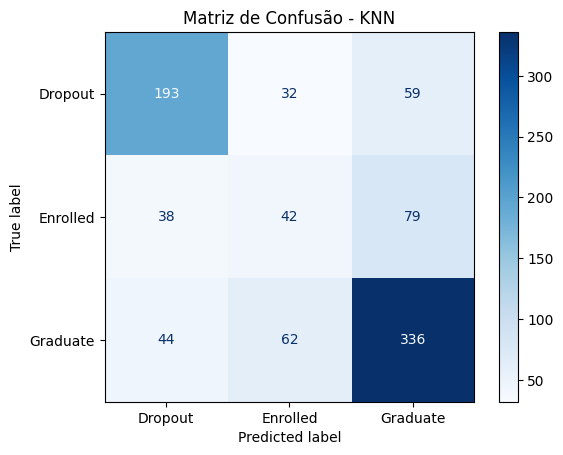


Relatório por classe:
              precision    recall  f1-score   support

     Dropout       0.70      0.68      0.69       284
    Enrolled       0.31      0.26      0.28       159
    Graduate       0.71      0.76      0.73       442

    accuracy                           0.65       885
   macro avg       0.57      0.57      0.57       885
weighted avg       0.63      0.65      0.64       885

Naive Bayes: 

Acurácia: 0.6588
Precisão: 0.6334
Recall: 0.6588
F1-score: 0.6417
Matriz de Confusão:


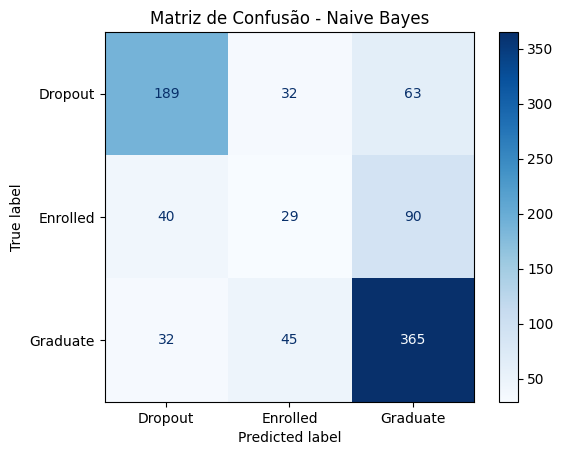


Relatório por classe:
              precision    recall  f1-score   support

     Dropout       0.72      0.67      0.69       284
    Enrolled       0.27      0.18      0.22       159
    Graduate       0.70      0.83      0.76       442

    accuracy                           0.66       885
   macro avg       0.57      0.56      0.56       885
weighted avg       0.63      0.66      0.64       885

Árvore de Decisão: 

Acurácia: 0.7130
Precisão: 0.7037
Recall: 0.7130
F1-score: 0.7066
Matriz de Confusão:


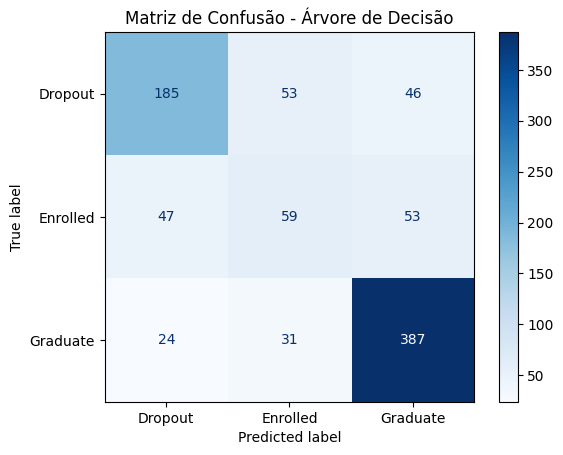


Relatório por classe:
              precision    recall  f1-score   support

     Dropout       0.72      0.65      0.69       284
    Enrolled       0.41      0.37      0.39       159
    Graduate       0.80      0.88      0.83       442

    accuracy                           0.71       885
   macro avg       0.64      0.63      0.64       885
weighted avg       0.70      0.71      0.71       885



,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNN,0.6452,0.6347,0.6452,0.6391
1,Naive Bayes,0.6588,0.6334,0.6588,0.6417
2,Árvore de Decisão,0.7130,0.7037,0.7130,0.7066


Melhor classificador: Árvore de Decisão
F1-score: 0.7066


In [52]:
# Previsões dos modelos
y_pred_knn = pipeline_knn.predict(X_teste)
y_pred_nb = pipeline_nb.predict(X_teste)
y_pred_arvore = pipeline_arvore.predict(X_teste)


# Função para calcular as métricas
def avaliar_modelo(nome, y_teste, y_pred, modelo):
    print(f"{nome}: \n") 

    # Métricas
    acuracia = accuracy_score(y_teste, y_pred)
    precisao = precision_score(y_teste, y_pred, average='weighted')
    recall = recall_score(y_teste, y_pred, average='weighted')
    f1 = f1_score(y_teste, y_pred, average='weighted')

    print(f"Acurácia: {acuracia:.4f}")
    print(f"Precisão: {precisao:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")

    # Matriz de confusão
    print("Matriz de Confusão:")
    matriz = confusion_matrix(y_teste, y_pred, labels=modelo.classes_)

    disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=modelo.classes_)

    disp.plot(cmap=plt.cm.Blues)

    plt.title(f'Matriz de Confusão - {nome}')
    plt.show()
    
    print("\nRelatório por classe:")
    print(classification_report(
        y_teste,
        y_pred,
        zero_division=0
    ))

# Avaliação dos modelos
avaliar_modelo('KNN', y_teste, y_pred_knn, pipeline_knn.named_steps['classificador'])
avaliar_modelo('Naive Bayes', y_teste, y_pred_nb, pipeline_nb.named_steps['classificador'])
avaliar_modelo('Árvore de Decisão', y_teste, y_pred_arvore, pipeline_arvore.named_steps['classificador'])

#Comparação dos modelos
resultados = []

modelos = {
    'KNN': (pipeline_knn, y_pred_knn),
    'Naive Bayes': (pipeline_nb, y_pred_nb),
    'Árvore de Decisão': (pipeline_arvore, y_pred_arvore)
}

for nome, (modelo, y_pred) in modelos.items():
    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste, y_pred),
        'Precisão': precision_score(y_teste, y_pred, average='weighted'),
        'Recall': recall_score(y_teste, y_pred, average='weighted'),
        'F1-score': f1_score(y_teste, y_pred, average='weighted')
    })

df_comparacao = pd.DataFrame(resultados)

display(df_comparacao.round(4))

#Desempenho geral
melhor_classificador = df_comparacao.loc[df_comparacao['F1-score'].idxmax()]
print(f"Melhor classificador: {melhor_classificador['Modelo']}")
print(f"F1-score: {melhor_classificador['F1-score']:.4f}")

## Comparação dos resultados

A tabela comparativa apresenta o desempenho dos três classificadores utilizando o mesmo conjunto de teste. Essa comparação permite observar qual modelo apresentou os melhores resultados nas métricas de avaliação.

De acordo com os resultados obtidos, a árvore de Decisão apresentou o melhor desempenho geral, destacando-se nas métricas de acurácia, precisão, recall e F1-score ponderado.

A acurácia indica o desempenho geral do modelo, mas não deve ser utilizada isoladamente. Como a base possui três classes com diferentes quantidades de registros, um classificador pode apresentar uma boa acurácia e, ainda assim, ter dificuldade para identificar corretamente uma das classes.

Por esse motivo, também foram analisadas a precisão, o recall, o F1-score e as matrizes de confusão, permitindo uma avaliação mais completa dos classificadores.

# Regressão
A base utilizada neste experimento foi Estimation of Obesity Levels Based On Eating Habits and Physical Condition, disponibilizada no repositório UCI Machine Learning Repository.

Fonte: https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition

In [53]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

## Seleção e Compreensão da Base
Origem da base: Os dados vem de um repositório no site di UCM (https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition). Os criadores juntaram os dados dos níveis de obesidade de indivíduos do México, Peru e Colômbia, incluindo os hábitos alimenatares e condições físicas.

Problema: Estimar o peso de indivíduos a partir de informações sobre seus hábitos alimentares, condições físicas e características pessoais.

Objetivo: Desenvolver e comparar modelos de regressão para prever o peso dos indivíduos, avaliando o desempenho do KNN, da Regressão Linear e da Árvore de Decisão.

A base reúne informações de indivíduos do México, Peru e Colômbia. Como o peso é uma variável numérica contínua, o problema é adequado para um experimento de regressão.

Número de linhas: 2111
Número de colunas: 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   ob

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


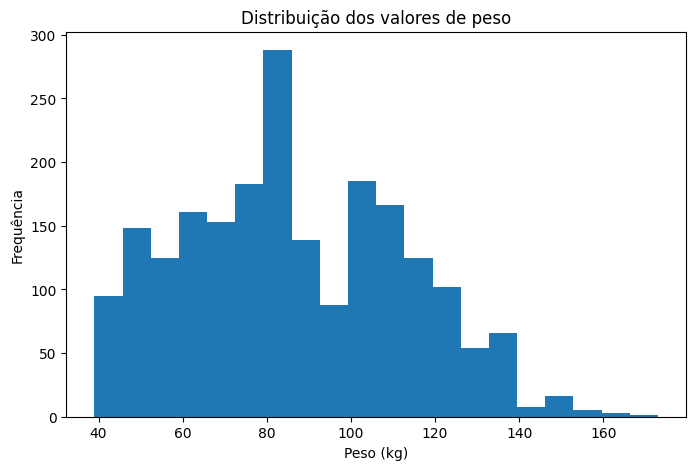

In [54]:
#Dataset estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition (obesidade para os mais próximos)
obesidade = fetch_ucirepo(id=544) 
df_obesidade = pd.concat([obesidade.data.features, obesidade.data.targets], axis=1)

linhas_obesidade = df_obesidade.shape[0]
colunas_obesidade = df_obesidade.shape[1]

print("Número de linhas:", linhas_obesidade)
print("Número de colunas:", colunas_obesidade)

df_obesidade.info()
display(df_obesidade.head())
display(df_obesidade.describe())

#Gráfico com a distribuição do peso
plt.figure(figsize=(8, 5))
plt.hist(df_obesidade['Weight'], bins=20)
plt.title("Distribuição dos valores de peso")
plt.xlabel("Peso (kg)")
plt.ylabel("Frequência")
plt.show()


## Preparação dos dados

A variável Weight foi escolhida como alvo por representar uma quantidade numérica contínua. A coluna NObeyesdad representa a categoria do nível de obesidade e não será utilizada como atributo preditor, evitando que informações diretamente relacionadas à variável-alvo influenciem o treinamento.

Os dados foram divididos em conjuntos de treinamento e teste, utilizando 80% para treinamento e 20% para teste.

Os valores ausentes são tratados por imputação. As variáveis categóricas são codificadas com One-Hot Encoding, e as variáveis numéricas são normalizadas com MinMaxScaler.

A normalização é importante para o KNN porque o algoritmo calcula distâncias entre os registros. Variáveis com escalas maiores podem dominar essas distâncias, prejudicando a influência das demais características.

In [60]:
valores_nulos_obesidade = df_obesidade.isnull().sum()
#print("Valores nulos por coluna:", valores_nulos_obesidade)

#A variável alvo é Weight 
x_obesidade = df_obesidade.drop(['Weight', 'NObeyesdad'], axis=1)
y_obesidade = df_obesidade['Weight']
print("Descrição:", y_obesidade.describe())

X_treino_obesidade, X_teste_obesidade, y_treino_obesidade, y_teste_obesidade = train_test_split(
    x_obesidade,
    y_obesidade,
    test_size=0.2,
    random_state=42
)

print("Treinamento:", X_treino_obesidade.shape)
print("Teste:", X_teste_obesidade.shape)

numericas = x_obesidade.select_dtypes(include=['number']).columns
categoricas = x_obesidade.select_dtypes(include=['object', 'category', 'bool']).columns

pipeline_numericas = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("escalonamento", MinMaxScaler())
])

pipeline_categoricas = Pipeline([
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

preprocessador_obesidade = ColumnTransformer([
    ("numericas", pipeline_numericas, numericas),
    ("categoricas", pipeline_categoricas, categoricas)
])

# Sem normalizações
pipeline_numericas_sem_norm = Pipeline([
    ("imputacao", SimpleImputer(strategy="median"))
])

preprocessador_sem_norm = ColumnTransformer([
    ("numericas", pipeline_numericas_sem_norm, numericas),
    ("categoricas", pipeline_categoricas, categoricas)
])

Descrição: count    2111.000000
mean       86.586058
std        26.191172
min        39.000000
25%        65.473343
50%        83.000000
75%       107.430682
max       173.000000
Name: Weight, dtype: float64
Treinamento: (1688, 15)
Teste: (423, 15)


## Treinamento e Comparação dos Regressores

Foram utilizados três algoritmos de regressão: KNN Regressor, Regressão Linear e Árvore de Decisão.

Para o KNN, foram testadas três configurações de vizinhos: 5, 10 e 15. A escolha da configuração foi realizada por validação cruzada com cinco divisões, utilizando somente os dados de treinamento.

Também foi realizada uma comparação entre o KNN com e sem normalização dos atributos.

In [61]:
# Validação cruzada com 5 divisões
cv = KFold(n_splits=5,shuffle=True,random_state=42)

# Configurações de k
parametros_knn = {"regressor__n_neighbors": [5, 10, 15]}

# KNN com normalização
pipeline_knn_norm = Pipeline([
    ("preprocessamento", preprocessador_obesidade),
    ("regressor", KNeighborsRegressor())
])

busca_knn_norm = GridSearchCV(
    estimator=pipeline_knn_norm,
    param_grid=parametros_knn,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

busca_knn_norm.fit(X_treino, y_treino)

# KNN SEM normalização
pipeline_knn_sem_norm = Pipeline([
    ("preprocessamento", preprocessador_sem_norm),
    ("regressor", KNeighborsRegressor())
])

busca_knn_sem_norm = GridSearchCV(
    estimator=pipeline_knn_sem_norm,
    param_grid=parametros_knn,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

busca_knn_sem_norm.fit(X_treino, y_treino)

print("KNN com normalização")
print("Melhor configuração:", busca_knn_norm.best_params_)
print("RMSE médio na validação:", -busca_knn_norm.best_score_)

print("\nKNN sem normalização")
print("Melhor configuração:", busca_knn_sem_norm.best_params_)
print("RMSE médio na validação:", -busca_knn_sem_norm.best_score_)


# Modelos para comparação
modelos_obesidade = {
    "KNN com normalização": busca_knn_norm.best_estimator_,
    "KNN sem normalização": busca_knn_sem_norm.best_estimator_,

    "Regressão Linear": Pipeline([
        ("preprocessamento", preprocessador_obesidade),
        ("regressor", LinearRegression())
    ]),

    "Árvore de Decisão": Pipeline([
        ("preprocessamento", preprocessador_obesidade),
        ("regressor", DecisionTreeRegressor(random_state=42))
    ])
}

resultados_obesidade = []
previsoes_obesidade = {}

for nome, modelo in modelos_obesidade.items():
    modelo.fit(X_treino, y_treino)
    y_pred = modelo.predict(X_teste)

    previsoes_obesidade[nome] = y_pred

    mae = mean_absolute_error(y_teste, y_pred)
    mse = mean_squared_error(y_teste, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_teste, y_pred)

    resultados_obesidade.append({
        "Modelo": nome,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

    print(f"\nResultados: {nome}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²: {r2:.4f}")

KNN com normalização
Melhor configuração: {'regressor__n_neighbors': 5}
RMSE médio na validação: 11.112769980914198

KNN sem normalização
Melhor configuração: {'regressor__n_neighbors': 5}
RMSE médio na validação: 13.651000125702819

Resultados: KNN com normalização
MAE: 6.8201
MSE: 131.2490
RMSE: 11.4564
R²: 0.8139

Resultados: KNN sem normalização
MAE: 6.8607
MSE: 128.5729
RMSE: 11.3390
R²: 0.8177

Resultados: Regressão Linear
MAE: 13.8194
MSE: 296.7836
RMSE: 17.2274
R²: 0.5791

Resultados: Árvore de Decisão
MAE: 5.7625
MSE: 124.6776
RMSE: 11.1659
R²: 0.8232


## Avaliação dos resultados

Os modelos foram avaliados por meio do Erro Absoluto Médio (MAE), Erro Quadrático Médio (MSE), Raiz do Erro Quadrático Médio (RMSE) e coeficiente de determinação (R²).

O MAE, MSE e RMSE indicam o erro das previsões, sendo melhores valores menores. O R² indica quanto da variação da variável-alvo é explicada pelo modelo, sendo desejável um valor mais próximo de 1.

Os resultados foram comparados por meio de uma tabela e gráficos, considerando também o efeito da normalização no desempenho do KNN.

,Modelo,MAE,MSE,RMSE,R²
3,Árvore de Decisão,5.762488,124.677561,11.165911,0.823180
1,KNN sem normalização,6.860694,128.572914,11.339000,0.817656
0,KNN com normalização,6.820067,131.248986,11.456395,0.813861
2,Regressão Linear,13.819448,296.783579,17.227408,0.579097


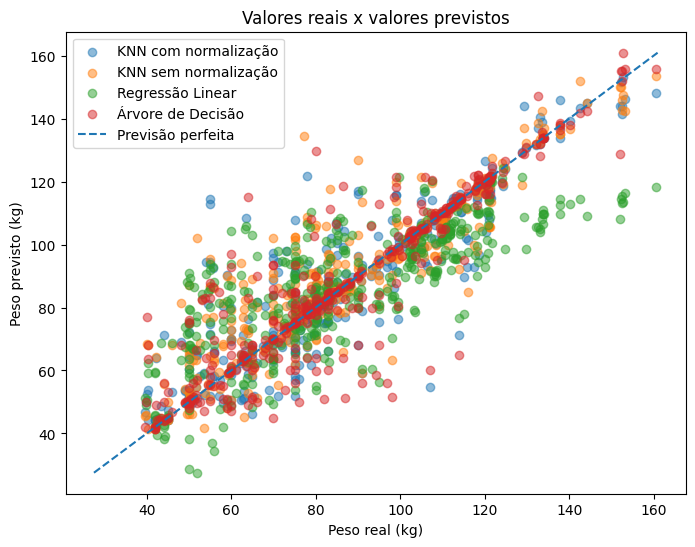

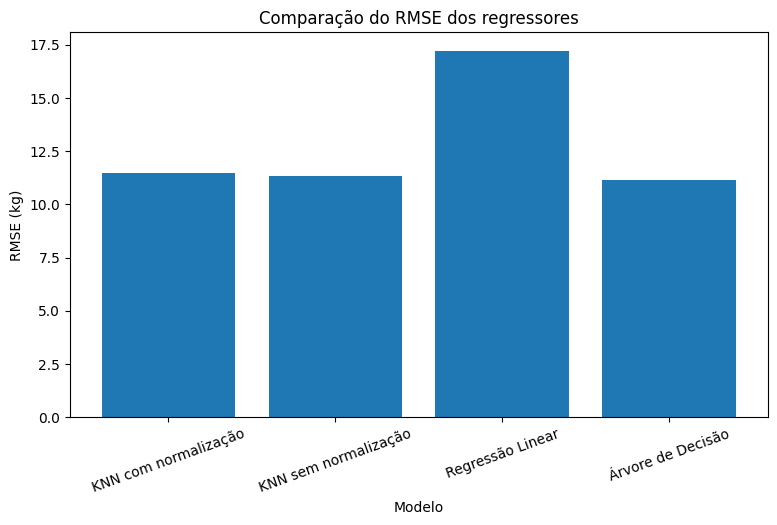

,Configuração,RMSE na validação cruzada
0,KNN com normalização,11.11277
1,KNN sem normalização,13.65100


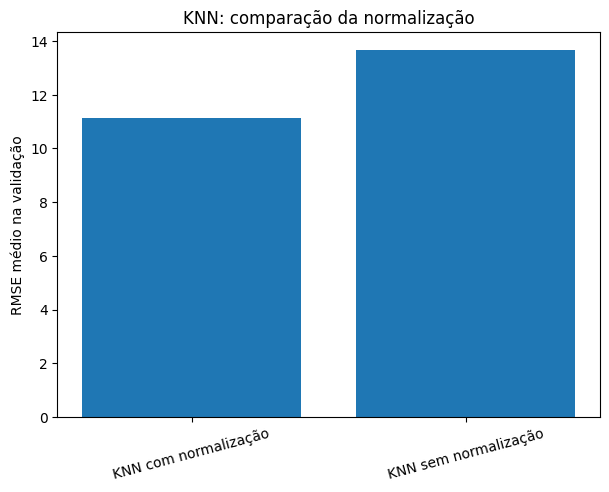

Melhor regressor: Árvore de Decisão
Menor RMSE: 11.1659


In [62]:
#Tabela de resultados
df_resultados_obesidade = pd.DataFrame(resultados_obesidade)
display(df_resultados_obesidade.sort_values(by="RMSE", ascending=True))
#Gráfico de valores reais e previstos
plt.figure(figsize=(8, 6))

for nome, modelo in modelos_obesidade.items():
    y_pred = modelo.predict(X_teste_obesidade)
    plt.scatter(y_teste_obesidade, y_pred, alpha=0.5, label=nome)

limite_min = min(y_teste_obesidade.min(), min(
    modelo.predict(X_teste_obesidade).min()
    for modelo in modelos_obesidade.values()
))

limite_max = max(y_teste_obesidade.max(), max(
    modelo.predict(X_teste_obesidade).max()
    for modelo in modelos_obesidade.values()
))

plt.plot([limite_min, limite_max],[limite_min, limite_max], linestyle="--", label="Previsão perfeita")
plt.title("Valores reais x valores previstos")
plt.xlabel("Peso real (kg)")
plt.ylabel("Peso previsto (kg)")
plt.legend()
plt.show()

#Gráfico comparativo dos regressores
plt.figure(figsize=(9, 5))
plt.bar(df_resultados_obesidade["Modelo"], df_resultados_obesidade["RMSE"])
plt.title("Comparação do RMSE dos regressores")
plt.xlabel("Modelo")
plt.ylabel("RMSE (kg)")
plt.xticks(rotation=20)
plt.show()

#Gráfico de comparação do KNN com e sem normalização
comparacao_normalizacao = pd.DataFrame({
    "Configuração": [
        "KNN com normalização",
        "KNN sem normalização"
    ],
    "RMSE na validação cruzada": [
        -busca_knn_norm.best_score_,
        -busca_knn_sem_norm.best_score_
    ]
})

display(comparacao_normalizacao)
plt.figure(figsize=(7, 5))
plt.bar(comparacao_normalizacao["Configuração"], comparacao_normalizacao["RMSE na validação cruzada"])
plt.title("KNN: comparação da normalização")
plt.ylabel("RMSE médio na validação")
plt.xticks(rotation=15)
plt.show()

#Melhor resultado
melhor_regressor = df_resultados_obesidade.loc[df_resultados_obesidade['RMSE'].idxmin()]
print(f"Melhor regressor: {melhor_regressor['Modelo']}")
print(f"Menor RMSE: {melhor_regressor['RMSE']:.4f}")

## Conclusão

Após a execução dos modelos, o regressor com melhor desempenho foi Regressão Linear, que apresentou o menor RMSE de 17.227408

A comparação entre o KNN com e sem normalização mostrou que a normalização não melhorou o desempenho, considerando o RMSE da validação cruzada.

As diferenças entre os modelos podem estar relacionadas à forma como cada algoritmo representa os dados. O KNN utiliza a distância entre registros, a Regressão Linear busca uma relação linear entre os atributos e a Árvore de Decisão realiza divisões sucessivas dos dados.

Portanto, os resultados demonstram que a escolha do algoritmo e o pré-processamento dos atributos influenciam o desempenho na estimativa do peso.